# Fichas explicables por sitio

<a href="https://colab.research.google.com/github/Niettzche/spaceapps-2026/blob/main/ciencia_datos/04_fichas_explicables.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

Para cada sitio de `data/sites/` con un cráter medido, esta ficha responde **por qué** el modelo dice lo que dice:

1. **Aporte de cada variable al modelo de forma.** El modelo Luna contra Marte es una regresión logística con 3 variables, así que su decisión se descompone de forma exacta: `logit(P_Luna) = intercepto + Σ coeficiente × valor estandarizado`. No es una aproximación como SHAP: es la cuenta completa.
2. **Gemelos más cercanos:** los 3 cráteres lunares y los 3 marcianos más parecidos, en el mismo espacio estandarizado que usa el modelo, con sus coordenadas.
3. **Puntaje por dimensión frente a cada destino:**
   - **forma:** el modelo de forma.
   - **terreno:** pendiente media en 10 km a 200 m.
   - **superficie:** vegetación (MODIS NDVI).
   - **clima:** NASA POWER, oscilación térmica y lluvia.

   El modelo calcula **5 dimensiones** (forma, oscilación térmica, lluvia, NDVI y pendiente). Aquí se agrupan en 4 para leerlas: "clima" junta oscilación térmica y lluvia. El total es la media geométrica ponderada de las 5 en `model/score.py`.

Salida: `ciencia_datos/salidas/fichas_explicables.json`, para la página web (`web/`). El juego no lo lee: solo usa `data/sites` (AGENTS.md §8.1).

In [1]:
import sys, json, subprocess
from pathlib import Path
REPO = "Niettzche/spaceapps-2026"
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "model" / "forma.py").exists()), None)
if RAIZ is None:
    try:
        from google.colab import userdata
        url = f"https://{userdata.get('GITHUB_TOKEN')}@github.com/{REPO}.git"
    except Exception:
        url = f"https://github.com/{REPO}.git"
    subprocess.run(["git", "clone", "--depth", "1", url, "/content/spaceapps-2026"], check=True)
    RAIZ = Path("/content/spaceapps-2026")
sys.path.insert(0, str(RAIZ))
SALIDA = RAIZ / "ciencia_datos" / "salidas"; SALIDA.mkdir(parents=True, exist_ok=True)

import math, numpy as np, pandas as pd, matplotlib.pyplot as plt
from model import forma
from model.score import comparar, DIMENSIONES

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
COL = {"Luna": "#8a8f98", "Marte": "#b5532f", "aporte+": "#5b6b8a", "aporte-": "#b5532f"}
NOMBRE_VAR = {"log_diam": "tamaño (log10 diámetro)", "prof_diam": "profundidad / diámetro", "borde_rel": "borde / diámetro"}
DESTINOS = {"polo_sur_lunar": "Luna (polo sur)", "jezero": "Marte (Jezero)"}
targets = {d: json.loads((RAIZ / "data" / "targets" / f"{d}.json").read_text(encoding="utf-8")) for d in DESTINOS}

sitios = [json.loads(p.read_text(encoding="utf-8")) for p in sorted((RAIZ / "data" / "sites").glob("*.json"))]
con_crater = [s for s in sitios if s["variables"].get("diametro", {}).get("valor") is not None]
print(f"Sitios en data/sites: {len(sitios)}; con cráter medido: {len(con_crater)}")
print(forma.resumen_modelo())

Sitios en data/sites: 56; con cráter medido: 54


{'corte95': 26.356, 'n_luna': 4288, 'n_marte': 573, 'variables': ['log_diam', 'prof_diam', 'borde_rel'], 'sitios_marte_excluidos': ['Elysium', 'Utopia']}


## 1. Cómo funciona la cuenta

La regresión logística tiene un coeficiente por variable estandarizada. Para un cráter, el aporte de cada variable es `coeficiente × z`, con `z = (valor − media) / desviación` de los cráteres de la Luna y Marte. Sumando el intercepto y los tres aportes sale el logit, y `P_Luna = 1 / (1 + e^(−logit))`. Abajo, los coeficientes del modelo, ya orientados hacia la Luna.

In [2]:
clf, *_ = forma._modelo()
esc, lr = clf[0], clf[-1]
signo = -1.0 if lr.classes_[1] == "Marte" else 1.0
coef = pd.DataFrame({"coeficiente hacia la Luna": signo * lr.coef_[0], "media": esc.mean_, "desviación": esc.scale_},
                    index=[NOMBRE_VAR[v] for v in forma.VARIABLES]).round(4)
print("Intercepto hacia la Luna:", round(float(signo * lr.intercept_[0]), 4))
coef

Intercepto hacia la Luna: 0.7428


,coeficiente hacia la Luna,media,desviación
tamaño (log10 diámetro),-0.3154,0.0858,0.2537
profundidad / diámetro,1.5642,0.0640,0.0375
borde / diámetro,-0.1977,-0.0229,0.0296


**Lectura:** el coeficiente de profundidad/diámetro es positivo y el más grande. Un cráter más hondo para su tamaño empuja hacia la Luna y uno más plano empuja hacia Marte. Las otras dos variables pesan menos. Es la misma regla que encontró el árbol de decisión del notebook 01.

## 2. Fichas de todos los sitios con cráter

In [3]:
GRUPOS = {"forma": ["forma"], "terreno": ["pendiente"], "superficie": ["ndvi"], "clima": ["oscilacion_termica", "precipitacion"]}

def dimensiones(s, destino):
    v = {k: x for k, x in s["variables"].items()}
    d, m = s["variables"]["diametro"]["valor"], s["variables"]["profundidad"]["valor"]
    b = s["variables"]["borde"]["valor"]
    v = {**v, "forma": {"valor": forma.forma_para(destino, d, m, b)["valor"]}}
    r = comparar(v, targets[destino]["variables"])
    out = {}
    for g, dims in GRUPOS.items():
        vals = [(r["por_dimension"].get(k), DIMENSIONES[k]["peso"]) for k in dims if r["por_dimension"].get(k) is not None]
        out[g] = None if not vals else round(math.exp(sum(w * math.log(max(x, 1e-9)) for x, w in vals) / sum(w for _, w in vals)), 4)
    out["total"] = r["total"]; out["confianza"] = r["confianza"]; out["vetado"] = r["vetado"]
    return out

fichas = {}
for s in con_crater:
    d, m, b = (s["variables"][k]["valor"] for k in ("diametro", "profundidad", "borde"))
    ex = forma.explicar(d, m, b)
    fichas[s["id"]] = {
        "nombre": s["nombre"], "pais": s.get("pais"), "lat": s["lat"], "lon": s["lon"], "estado": s["estado"],
        "destino_ref": s["destino_ref"], "proceso": s.get("proceso"), "novedoso": s.get("novedoso"),
        "medidas": {"diam_km": d, "prof_m": m, "prof_diam": s["variables"]["profundidad_diametro"]["valor"], "borde_m": b},
        "forma_explicada": ex,
        "gemelos": forma.gemelos_knn(d, m, b, k=3),
        "dimensiones": {dest: dimensiones(s, dest) for dest in DESTINOS},
    }
(SALIDA / "fichas_explicables.json").write_text(json.dumps(fichas, ensure_ascii=False, indent=1), encoding="utf-8")
tabla = pd.DataFrame([{"id": k, "nombre": f["nombre"][:38], "P_Luna": f["forma_explicada"]["P_Luna"],
                       **{f"total {DESTINOS[d].split(' ')[0]}": f["dimensiones"][d]["total"] for d in DESTINOS},
                       "aporte d/D": f["forma_explicada"]["aportes"]["prof_diam"]["aporte_logit"]} for k, f in fichas.items()])
print(f"Fichas escritas: {len(fichas)} → {SALIDA / 'fichas_explicables.json'}")
tabla.sort_values("P_Luna", ascending=False).round(3).head(15)

Fichas escritas: 54 → /home/mario/sa-modelo-datos/ciencia_datos/salidas/fichas_explicables.json


,id,nombre,P_Luna,total Luna,total Marte,aporte d/D
48,mx0207,Real de Ángeles (Zac.),1.000,0.193,0.000,9.413
37,mx0085,Hércules (Coah.),1.000,0.299,0.000,8.058
36,mx0084,Hércules (Coah.),0.999,0.416,0.030,6.242
44,mx0155,Peñasquito (Zac.),0.996,0.534,0.054,5.180
5,g00071,Depresión tipo cráter G00071 (Atacama,0.995,0.728,0.090,4.593
6,g00174,Depresión tipo cráter G00174 (Arizona,0.993,0.560,0.066,4.000
9,g00219,Depresión tipo cráter G00219 (Arizona,0.991,0.611,0.098,3.967
10,g00240,Depresión tipo cráter G00240 (Arizona,0.990,0.627,0.110,4.183
8,g00216,Depresión tipo cráter G00216 (Arizona,0.989,0.561,0.081,3.840
1,g00013,Depresión tipo cráter G00013 (Atacama,0.988,0.722,0.116,3.829


## 3. Sitios destacados, explicados

Se muestran seis casos: el control (El Elegante, Pinacate), un maar documentado (Rincón de Parangueo), dos tajos mineros de México (Cananea y Peñasquito), el candidato global de Atacama con mejor forma y el candidato más "marciano" de México.

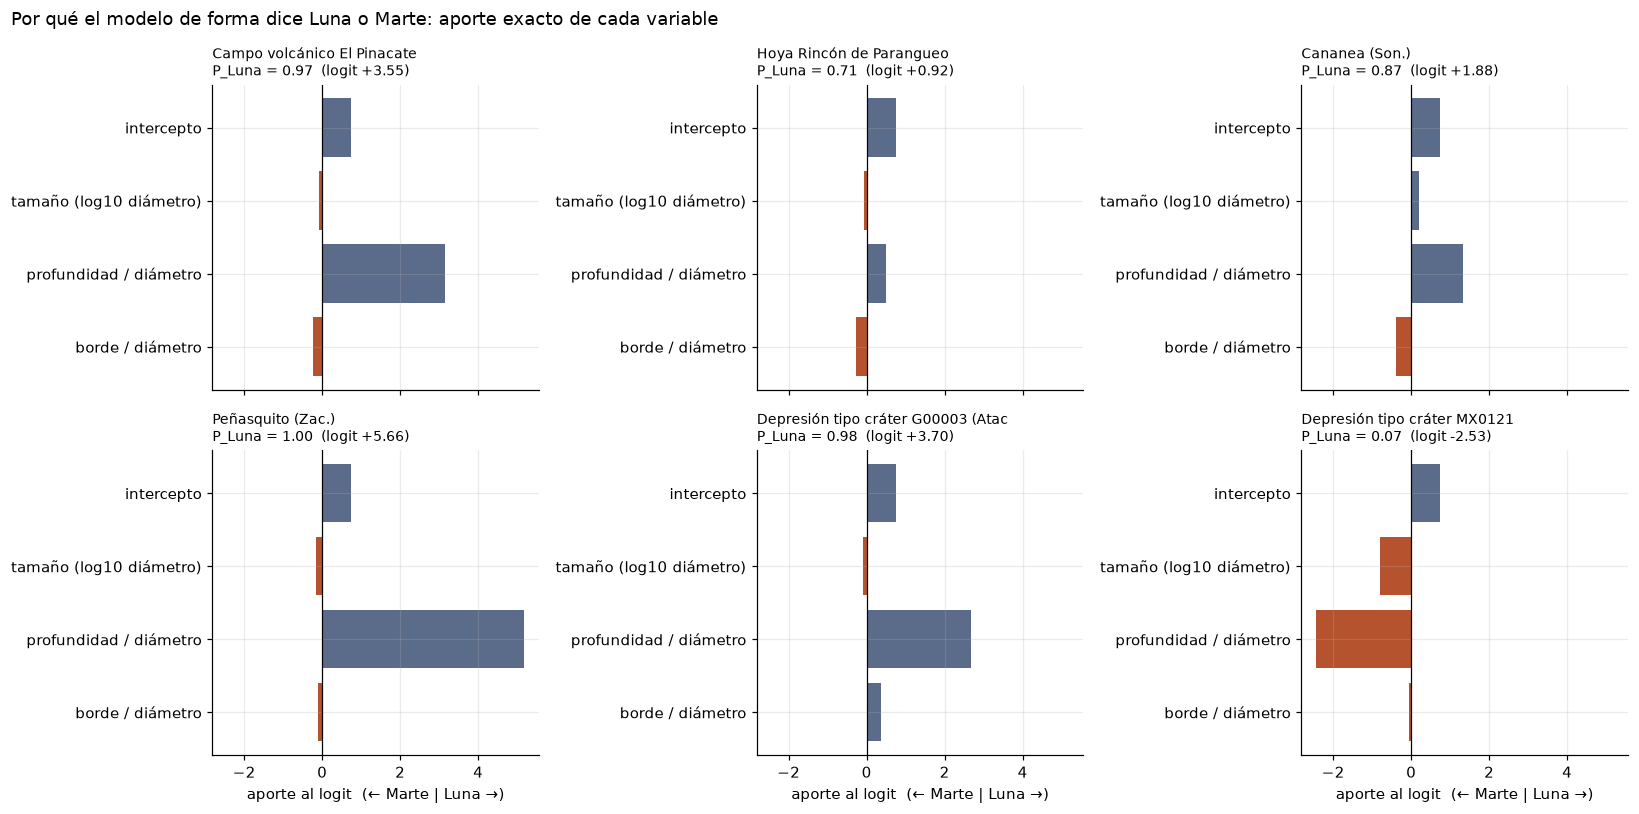

In [4]:
mas_marciano = min((k for k in fichas if k.startswith("mx")), key=lambda k: fichas[k]["forma_explicada"]["P_Luna"])
mejor_global = max((k for k in fichas if k.startswith("g")), key=lambda k: fichas[k]["dimensiones"]["polo_sur_lunar"]["total"] or 0)
DEST = [k for k in ["pinacate", "mx0261", "mx0023", "mx0155", mejor_global, mas_marciano] if k in fichas]

fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
for ax, k in zip(axs.ravel(), DEST):
    f = fichas[k]; ex = f["forma_explicada"]
    nombres = ["intercepto"] + [NOMBRE_VAR[v] for v in forma.VARIABLES]
    vals = [ex["intercepto"]] + [ex["aportes"][v]["aporte_logit"] for v in forma.VARIABLES]
    ax.barh(nombres[::-1], vals[::-1], color=[COL["aporte+"] if x >= 0 else COL["aporte-"] for x in vals[::-1]])
    ax.axvline(0, color="k", lw=.8)
    ax.set_title(f"{f['nombre'][:34]}\nP_Luna = {ex['P_Luna']:.2f}  (logit {ex['logit_luna']:+.2f})", fontsize=9, loc="left")
for ax in axs[-1]: ax.set_xlabel("aporte al logit  (← Marte | Luna →)")
fig.suptitle("Por qué el modelo de forma dice Luna o Marte: aporte exacto de cada variable", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(SALIDA / "fichas_aportes.png", bbox_inches="tight"); plt.show()

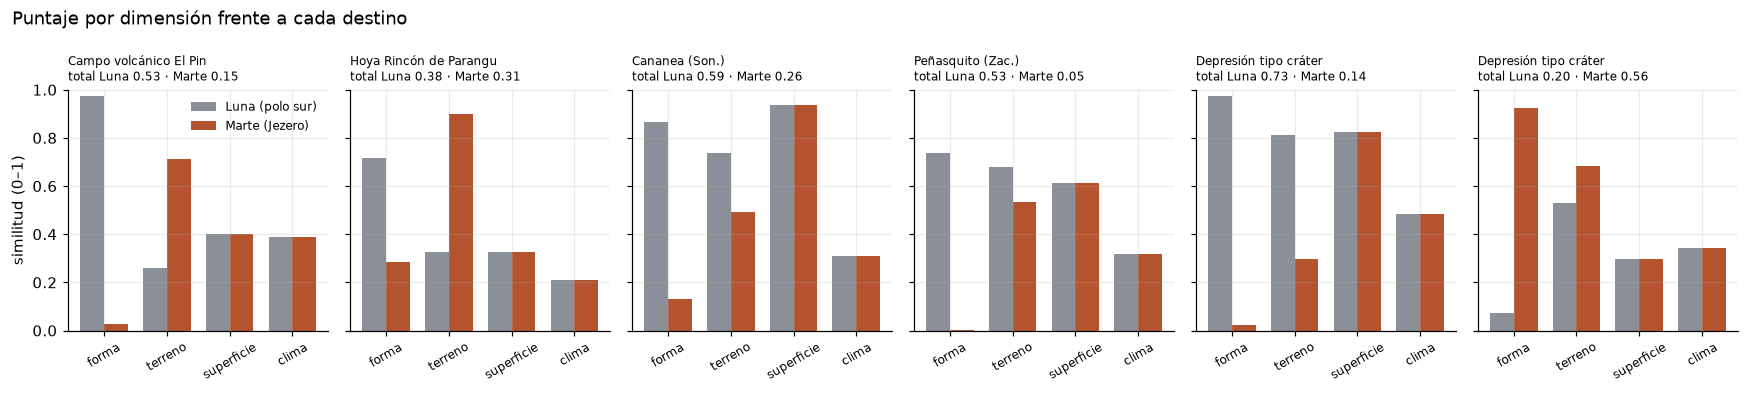

In [5]:
grupos = list(GRUPOS)
fig, axs = plt.subplots(1, len(DEST), figsize=(16, 3.6), sharey=True)
for ax, k in zip(axs, DEST):
    f = fichas[k]
    x = np.arange(len(grupos)); w = .38
    for i, (dest, color) in enumerate([("polo_sur_lunar", COL["Luna"]), ("jezero", COL["Marte"])]):
        vals = [f["dimensiones"][dest][g] if f["dimensiones"][dest][g] is not None else 0 for g in grupos]
        ax.bar(x + (i - .5) * w, vals, w, color=color, label=DESTINOS[dest] if k == DEST[0] else None)
    ax.set_xticks(x); ax.set_xticklabels(grupos, rotation=30, fontsize=8); ax.set_ylim(0, 1)
    tl, tm = f["dimensiones"]["polo_sur_lunar"]["total"], f["dimensiones"]["jezero"]["total"]
    ax.set_title(f"{f['nombre'][:22]}\ntotal Luna {tl:.2f} · Marte {tm:.2f}", fontsize=8, loc="left")
axs[0].set_ylabel("similitud (0–1)"); axs[0].legend(frameon=False, fontsize=8)
fig.suptitle("Puntaje por dimensión frente a cada destino", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(SALIDA / "fichas_dimensiones.png", bbox_inches="tight"); plt.show()

In [6]:
for k in DEST:
    f = fichas[k]
    print(f"\n{f['nombre']}  ({k})  — d/D {f['medidas']['prof_diam']}, {f['medidas']['diam_km']} km")
    for cuerpo in ("Luna", "Marte"):
        g = f["gemelos"][cuerpo][0]
        print(f"  gemelo {cuerpo:5s}: {g['sitio']}, {g['lat']}, {g['lon']} — {g['diam_km']} km, {g['prof_m']} m, d/D {g['prof_diam']} (distancia z {g['distancia_z']})")


Campo volcánico El Pinacate  (pinacate)  — d/D 0.1392, 1.445 km
  gemelo Luna : Anillo 80-85°S, -80.728, -80.783 — 1.35 km, 180 m, d/D 0.133 (distancia z 0.208)
  gemelo Marte: Oxia Planum, 17.484, -23.526 — 1.48 km, 206 m, d/D 0.139 (distancia z 0.045)

Hoya Rincón de Parangueo  (mx0261)  — d/D 0.0762, 1.373 km
  gemelo Luna : Anillo 80-85°S, -82.402, 120.337 — 1.35 km, 105 m, d/D 0.078 (distancia z 0.061)
  gemelo Marte: Gusev (Spirit), -15.16, 175.192 — 1.08 km, 80 m, d/D 0.074 (distancia z 0.655)

Cananea (Son.)  (mx0023)  — d/D 0.0957, 0.844 km
  gemelo Luna : Anillo 80-85°S, -81.268, -84.605 — 0.96 km, 102 m, d/D 0.107 (distancia z 0.379)
  gemelo Marte: Oxia Planum, 18.524, -23.546 — 0.93 km, 70 m, d/D 0.075 (distancia z 1.053)

Peñasquito (Zac.)  (mx0155)  — d/D 0.188, 1.658 km
  gemelo Luna : Polo sur (85-90°S), -85.718, -80.908 — 1.66 km, 278 m, d/D 0.167 (distancia z 0.551)
  gemelo Marte: Cráter Jezero, 18.97, 77.592 — 3.02 km, 574 m, d/D 0.19 (distancia z 1.3)

Depresión 

### Lectura

- **Casi todo lo decide profundidad/diámetro.** En los cinco primeros casos, esa barra domina; el tamaño y el borde apenas mueven la decisión. Peñasquito sale lunar con un logit de +5.7, casi todo por su d/D de 0.19. El candidato más marciano (MX0121, una cuenca de 5.3 km casi plana) sale hacia Marte por la misma variable, en sentido contrario.
- **Gemelo cercano y probabilidad no son lo mismo.** El Elegante tiene un gemelo casi idéntico en Oxia Planum (distancia z 0.05), aunque el modelo le da P_Luna 0.97: un cráter hondo para su tamaño es mucho más común en la Luna que en Marte, aunque en Marte también existan. En el pitch conviene decir "más típico de la Luna", no "imposible en Marte".
- **Rincón de Parangueo queda a medio camino** (P_Luna 0.71). Su gemelo lunar es casi exacto (z 0.06), pero su d/D (0.076) es común en los dos cuerpos.
- **El total por destino combina forma, terreno, superficie y clima.** Para la Luna, los mejores totales son los probables tajos de Atacama (0.71–0.73) y, en México, Cananea (0.59). Frente a Marte, ningún cráter con d/D > 0.1 pasa de 0.20, porque su forma es poco marciana.

## 4. Límites de estas fichas

- **El aporte por variable es exacto solo para la forma**, porque es un modelo lineal. Las demás dimensiones son similitudes directas (`exp(−|Δ|/escala)`) y no tienen nada que descomponer.
- **Los gemelos se buscan con las mismas 3 variables del modelo, a 200 m.** No incluyen el perfil de la pared ni del fondo; eso llega con `perfiles_radiales.csv` (analisis/17), solo para la Luna.
- **La dimensión de clima no distingue la Luna de Marte.** El comparador recorta la oscilación térmica de los dos destinos al máximo terrestre (40 K), así que favorece los desiertos sin importar el destino. La que sí separa los mundos es la forma.
- **Gravedad, vacío, radiación e iluminación polar no entran en ningún puntaje.** Se declaran en `limites` de cada sitio.